In [10]:
import duckdb


In [11]:
from pathlib import Path

print("Current directory:", Path.cwd())

print("Business parquet exists:",
      Path("../data/parquet/business.parquet").exists())

print("Parquet files:",
      list(Path("../data/parquet").glob("*.parquet")))

Current directory: c:\Users\vaish\Documents\GitHub\yelp-bi-copilot\notebooks
Business parquet exists: True
Parquet files: [WindowsPath('../data/parquet/business.parquet'), WindowsPath('../data/parquet/review.parquet'), WindowsPath('../data/parquet/tip.parquet'), WindowsPath('../data/parquet/user.parquet')]


In [12]:
import duckdb

con = duckdb.connect()

con.sql("""
    SELECT city, state,
           COUNT(*) AS businesses,
           SUM(review_count) AS reviews
    FROM '../data/parquet/business.parquet'
    WHERE categories LIKE '%Restaurants%'
    GROUP BY 1, 2
    ORDER BY reviews DESC
    LIMIT 25
""").show()

┌────────────────┬─────────┬────────────┬─────────┐
│      city      │  state  │ businesses │ reviews │
│    varchar     │ varchar │   int64    │ int128  │
├────────────────┼─────────┼────────────┼─────────┤
│ Philadelphia   │ PA      │       5852 │  665732 │
│ New Orleans    │ LA      │       2259 │  465982 │
│ Nashville      │ TN      │       2502 │  318548 │
│ Tampa          │ FL      │       2960 │  293122 │
│ Indianapolis   │ IN      │       2862 │  242024 │
│ Tucson         │ AZ      │       2466 │  238851 │
│ Reno           │ NV      │       1286 │  191003 │
│ Saint Louis    │ MO      │       1790 │  171777 │
│ Santa Barbara  │ CA      │        767 │  158247 │
│ Boise          │ ID      │        847 │   64366 │
│   ·            │ ·       │         ·  │     ·   │
│   ·            │ ·       │         ·  │     ·   │
│   ·            │ ·       │         ·  │     ·   │
│ Sparks         │ NV      │        334 │   38205 │
│ Franklin       │ TN      │        442 │   36726 │
│ St. Peters

In [13]:
con.sql("""
    SELECT
        city,
        state,
        COUNT(*) AS businesses,
        SUM(review_count) AS reviews
    FROM '../data/parquet/business.parquet'
    WHERE categories LIKE '%Restaurants%'
    GROUP BY city, state
    HAVING SUM(review_count) BETWEEN 20000 AND 100000
    ORDER BY reviews DESC
    LIMIT 30
""").show()

┌──────────────────┬─────────┬────────────┬─────────┐
│       city       │  state  │ businesses │ reviews │
│     varchar      │ varchar │   int64    │ int128  │
├──────────────────┼─────────┼────────────┼─────────┤
│ Boise            │ ID      │        847 │   64366 │
│ Edmonton         │ AB      │       2166 │   61692 │
│ Clearwater       │ FL      │        678 │   54354 │
│ Saint Petersburg │ FL      │        491 │   51018 │
│ St. Louis        │ MO      │        542 │   44385 │
│ Metairie         │ LA      │        522 │   40631 │
│ Sparks           │ NV      │        334 │   38205 │
│ Franklin         │ TN      │        442 │   36726 │
│ St. Petersburg   │ FL      │        404 │   34890 │
│ Wilmington       │ DE      │        619 │   30322 │
│ Brandon          │ FL      │        326 │   28942 │
│ Carmel           │ IN      │        291 │   26356 │
│ Goleta           │ CA      │        220 │   25721 │
│ Cherry Hill      │ NJ      │        297 │   23935 │
│ Meridian         │ ID     

In [14]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate project root
PROJECT_ROOT = Path.cwd().parent

# Connect to existing database
DB_PATH = PROJECT_ROOT / "yelp.duckdb"
con = duckdb.connect(str(DB_PATH), read_only=True)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Database connected:", DB_PATH.exists())

Database connected: True


In [15]:
con.sql("SHOW TABLES").show()

┌────────────────┐
│      name      │
│    varchar     │
├────────────────┤
│ business_slice │
│ review_slice   │
│ tip_slice      │
│ user_slice     │
└────────────────┘



### Ratings analysis

#### Business star distribution

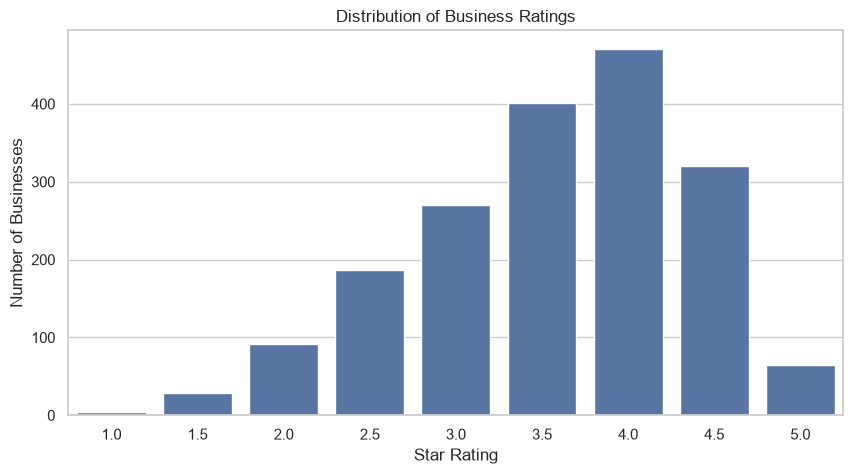

,stars,business_count
0,1.0,4
1,1.5,29
2,2.0,91
3,2.5,187
4,3.0,270
5,3.5,401
6,4.0,471
7,4.5,320
8,5.0,64


In [24]:
business_ratings = con.sql("""
    SELECT stars, COUNT(*) AS business_count
    FROM business_slice
    GROUP BY stars
    ORDER BY stars
""").df()

sns.barplot(data=business_ratings, x="stars", y="business_count")
plt.title("Distribution of Business Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Businesses")
plt.show()

display(business_ratings)

#### Review star distribution

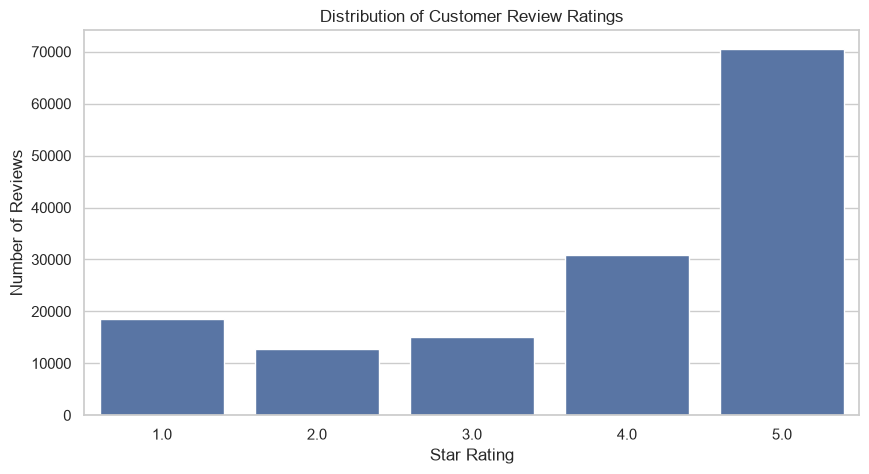

,stars,review_count
0,1.0,18573
1,2.0,12713
2,3.0,15039
3,4.0,30833
4,5.0,70601


In [26]:
review_ratings = con.sql("""
    SELECT stars, COUNT(*) AS review_count
    FROM review_slice
    GROUP BY stars
    ORDER BY stars
""").df()

sns.barplot(data=review_ratings, x="stars", y="review_count")
plt.title("Distribution of Customer Review Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.show()

display(review_ratings)

### Review volume and seasonality

#### Monthly review volume

In [27]:
monthly_reviews = con.sql("""
    SELECT
        DATE_TRUNC('month', CAST(review_date AS DATE)) AS review_month,
        COUNT(*) AS total_reviews
    FROM review_slice
    GROUP BY 1
    ORDER BY 1
""").df()

plt.figure(figsize=(14, 5))
sns.lineplot(
    data=monthly_reviews,
    x="review_month",
    y="total_reviews"
)

plt.title("Monthly Yelp Review Volume")
plt.xlabel("Month")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

BinderException: Binder Error: Referenced column "review_date" not found in FROM clause!
Candidate bindings: "review_id", "user_id"

In [28]:
pandemic_analysis = con.sql("""
    SELECT
        CASE
            WHEN review_date < DATE '2020-03-01' THEN 'Pre-pandemic'
            WHEN review_date <= DATE '2021-12-31' THEN 'Pandemic'
            ELSE 'Post-pandemic'
        END AS period,
        COUNT(*) AS total_reviews
    FROM review_slice
    GROUP BY 1
""").df()

display(pandemic_analysis)

sns.barplot(
    data=pandemic_analysis,
    x="period",
    y="total_reviews"
)
plt.title("Review Volume Across Pandemic Periods")
plt.xlabel("Period")
plt.ylabel("Number of Reviews")
plt.show()

BinderException: Binder Error: Referenced column "review_date" not found in FROM clause!
Candidate bindings: "review_id", "user_id"